# RouteVision：改進實驗（輪流測試 + 資料增強 + 集成）

第一版只用 Vortex-small 當測試設計。這份 notebook 做三件事：

1. **Leave-one-design-out**：Vortex-small、nvdla-small、openc910-1 輪流當「完全沒參與訓練」的測試設計，回答「只測一個設計可信嗎」。
2. **資料增強**：訓練時隨機左右、上下鏡像整張版圖（區塊位置特徵跟著鏡像；標註不變）。每個測試設計都跑「無增強」與「有增強」兩組，直接比較。
3. **集成（Ensemble）**：Random Forest、Multimodal、ViT 的機率取平均，不需額外訓練；閾值一樣在驗證集決定。

最後依「3 個測試設計平均」選出較好的設定，把 Vortex-small 那一輪的模型匯出給網頁 demo 使用（舊模型保留在 `checkpoints_v1/`）。

### 執行步驟（Colab，T4 GPU，約 50–60 分鐘）
1. 把 `RouteVision_v2.zip` 上傳到 Google Drive 的 `MyDrive/`（和第一版放同一個地方）。
2. 「執行階段 → 變更執行階段類型」選 **T4 GPU**。
3. 「執行階段 → 全部執行」。每一輪的模型存在 Drive 的 `MyDrive/RouteVision/checkpoints_lodo/`，斷線後重跑會從中斷處繼續。
4. 最後一格會下載 `RouteVision_results_v2.zip`；解壓到本機專案資料夾即可（會覆蓋 `checkpoints/`、`outputs/`、`demo/`）。

In [1]:
# 環境設定：掛載 Drive；解壓新版程式（覆蓋程式碼，但不覆蓋已存在的資料與模型）
import os, sys, json, shutil
from google.colab import drive
drive.mount('/content/drive')
PROJECT = '/content/drive/MyDrive/RouteVision'
ZIP = '/content/drive/MyDrive/RouteVision_v2.zip'
!unzip -q -n {ZIP} -d /content/drive/MyDrive/
!unzip -q -o {ZIP} 'RouteVision/routevision/*' 'RouteVision/app/*' 'RouteVision/notebooks/*' 'RouteVision/tests/*' 'RouteVision/README.md' 'RouteVision/requirements.txt' -d /content/drive/MyDrive/
os.chdir(PROJECT); sys.path.insert(0, PROJECT)
%matplotlib inline
import torch
print('device:', torch.cuda.get_device_name(0) if torch.cuda.is_available() else 'CPU（請改用 T4 GPU）')

Mounted at /content/drive
device: Tesla T4


## 1. 沿用第一版的模型
第一版就是「測試 Vortex-small、無增強」這一輪，程式完全相同，所以直接沿用 `checkpoints/` 的模型，省下約 10 分鐘。
只有在目標資料夾還沒有模型、而且來源確實是無增強訓練的模型時才會複製。

In [2]:
DESIGNS = ['Vortex-small', 'nvdla-small', 'openc910-1']
CK_ROOT, OUT_ROOT = 'checkpoints_lodo', 'outputs/lodo'
src = 'checkpoints_v1' if os.path.exists('checkpoints_v1') else 'checkpoints'
dst = f'{CK_ROOT}/Vortex-small/no_aug'
os.makedirs(dst, exist_ok=True)
for m in ['MLP', 'CNN', 'Multimodal', 'ViT']:
    js = f'{src}/{m}.json'
    if os.path.exists(f'{src}/{m}.pt') and os.path.exists(js) and not os.path.exists(f'{dst}/{m}.pt') \
            and not json.load(open(js)).get('augment', False):
        shutil.copy2(f'{src}/{m}.pt', dst); shutil.copy2(js, dst); print('reuse', m)
if os.path.exists(f'{src}/RandomForest.joblib') and not os.path.exists(f'{dst}/RandomForest.joblib'):
    shutil.copy2(f'{src}/RandomForest.joblib', dst); print('reuse RandomForest')

reuse MLP
reuse CNN
reuse Multimodal
reuse ViT
reuse RandomForest


## 2. 輪流測試 × 有無資料增強
3 個測試設計 × 2 種設定。每一輪：在其餘兩個設計上訓練（85% 訓練、15% 驗證），閾值在驗證集決定，只在測試設計上評估。

In [3]:
from routevision import experiments as E
import pandas as pd
pd.set_option('display.width', 220); pd.set_option('display.max_columns', 30)
df, summary = E.cross_design('data/processed', DESIGNS, ckpt_root=CK_ROOT, out_root=OUT_ROOT)
summary


=== test design: Vortex-small ===
train:  164 layouts,  10496 windows, hotspot rate 0.388, designs ['nvdla-small', 'openc910-1']
val  :   28 layouts,   1792 windows, hotspot rate 0.390, designs ['nvdla-small', 'openc910-1']
test :   96 layouts,   6144 windows, hotspot rate 0.232, designs ['Vortex-small']
--- no_aug ---
[cache] RandomForest
[cache] MLP: best epoch 10, val ROC-AUC 0.9894
[cache] CNN: best epoch 14, val ROC-AUC 0.9976
[cache] Multimodal: best epoch 14, val ROC-AUC 0.9984
Downloading: "https://download.pytorch.org/models/vit_b_16-c867db91.pth" to /root/.cache/torch/hub/checkpoints/vit_b_16-c867db91.pth


100%|██████████| 330M/330M [00:02<00:00, 127MB/s]


[cache] ViT: best epoch 3, val ROC-AUC 0.9976
train:  164 layouts,  10496 windows, hotspot rate 0.388, designs ['nvdla-small', 'openc910-1']
val  :   28 layouts,   1792 windows, hotspot rate 0.390, designs ['nvdla-small', 'openc910-1']
test :   96 layouts,   6144 windows, hotspot rate 0.232, designs ['Vortex-small']
--- aug ---
  [MLP] epoch  1/15 | loss 0.4752 | val ROC-AUC 0.9820 | 2s
  [MLP] epoch  2/15 | loss 0.2628 | val ROC-AUC 0.9757 | 2s
  [MLP] epoch  3/15 | loss 0.2291 | val ROC-AUC 0.9831 | 3s
  [MLP] epoch  4/15 | loss 0.2218 | val ROC-AUC 0.9832 | 6s
  [MLP] epoch  5/15 | loss 0.2155 | val ROC-AUC 0.9824 | 2s
  [MLP] epoch  6/15 | loss 0.2091 | val ROC-AUC 0.9844 | 2s
  [MLP] epoch  7/15 | loss 0.2006 | val ROC-AUC 0.9844 | 2s
  [MLP] epoch  8/15 | loss 0.1896 | val ROC-AUC 0.9860 | 2s
  [MLP] epoch  9/15 | loss 0.1844 | val ROC-AUC 0.9859 | 2s
  [MLP] epoch 10/15 | loss 0.1847 | val ROC-AUC 0.9872 | 3s
  [MLP] epoch 11/15 | loss 0.1797 | val ROC-AUC 0.9860 | 2s
  [MLP] ep

,setting,method,ROC-AUC mean,ROC-AUC std,PR-AUC mean,PR-AUC std,F1(hotspot) mean,F1(hotspot) std,Macro-F1 mean,Macro-F1 std,mean_layout_F1 mean,mean_layout_F1 std,layouts_beating_eGR
0,no_aug,RUDY (EDA estimate),0.8809,0.0613,0.6516,0.2795,0.6578,0.2413,0.7595,0.0906,0.6755,0.2143,84 / 288
1,no_aug,eGR (EDA estimate),0.9111,0.0689,0.7183,0.2615,0.6697,0.2652,0.7855,0.1119,0.6951,0.2253,(reference)
2,no_aug,OpenCV + RandomForest,0.9667,0.0195,0.8962,0.0807,0.7596,0.0752,0.8198,0.0160,0.7169,0.1133,137 / 288
3,no_aug,MLP,0.9321,0.0430,0.7253,0.2445,0.7067,0.2193,0.7992,0.1001,0.6896,0.2313,143 / 288
4,no_aug,CNN,0.9519,0.0254,0.8358,0.1295,0.7518,0.1433,0.8308,0.0494,0.6650,0.2410,123 / 288
5,no_aug,Multimodal,0.9648,0.0132,0.8674,0.1053,0.7842,0.1178,0.8497,0.0321,0.6999,0.2205,128 / 288
6,no_aug,ViT,0.9524,0.0213,0.8038,0.2015,0.7403,0.1363,0.8146,0.0402,0.6973,0.1852,131 / 288
7,no_aug,Ensemble,0.9702,0.0129,0.8905,0.0975,0.7816,0.1103,0.8442,0.0253,0.7282,0.1764,139 / 288
8,aug,RUDY (EDA estimate),0.8809,0.0613,0.6516,0.2795,0.6578,0.2413,0.7595,0.0906,0.6755,0.2143,84 / 288
9,aug,eGR (EDA estimate),0.9111,0.0689,0.7183,0.2615,0.6697,0.2652,0.7855,0.1119,0.6951,0.2253,(reference)


## 3. 結果
- 長條：3 個測試設計的平均；黑點：各個測試設計。
- `layouts_beating_eGR`：逐張版圖比較 F1，贏過 eGR 的版圖數（3 個設計共 288 張）。

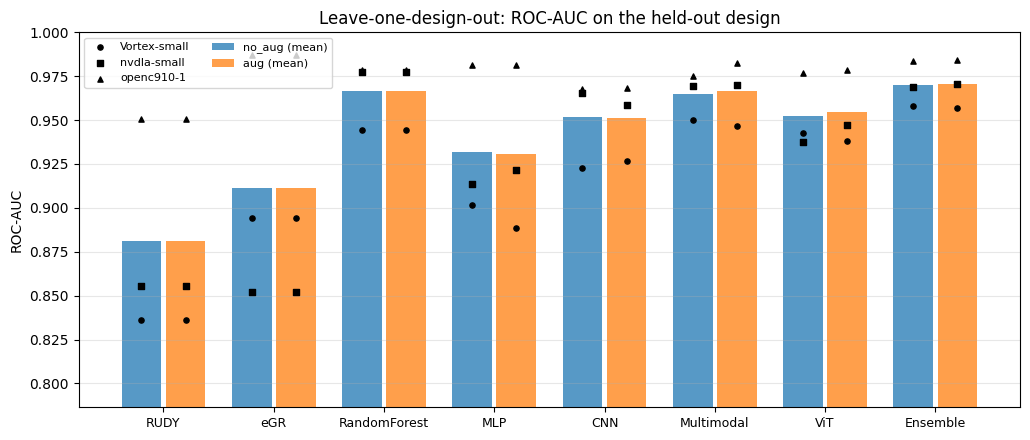

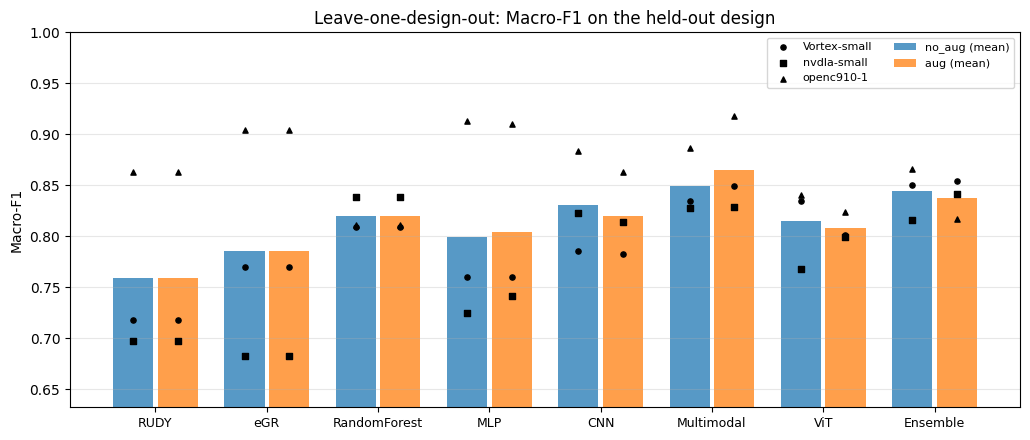

setting,no_aug,aug,no_aug,aug,no_aug,aug
test_design,Vortex-small,Vortex-small,nvdla-small,nvdla-small,openc910-1,openc910-1
method,,,,,,
RUDY (EDA estimate),0.8364,0.8364,0.8555,0.8555,0.9508,0.9508
eGR (EDA estimate),0.8942,0.8942,0.8522,0.8522,0.9869,0.9869
OpenCV + RandomForest,0.9442,0.9442,0.9772,0.9772,0.9788,0.9788
MLP,0.9014,0.8885,0.9136,0.9218,0.9813,0.9813
CNN,0.9226,0.9268,0.9656,0.9586,0.9675,0.9683
Multimodal,0.9499,0.9468,0.9696,0.9701,0.9749,0.9823
ViT,0.9425,0.9382,0.9378,0.9472,0.9768,0.9783
Ensemble,0.9580,0.9569,0.9688,0.9708,0.9837,0.9841


In [4]:
import matplotlib.pyplot as plt
E.plot_cross_design(df, f'{OUT_ROOT}/cross_design_roc_auc.png', 'ROC-AUC'); plt.show()
E.plot_cross_design(df, f'{OUT_ROOT}/cross_design_macro_f1.png', 'Macro-F1'); plt.show()
df.pivot_table(index='method', columns=['setting', 'test_design'], values='ROC-AUC', sort=False).round(4)

## 4. 選出設定並匯出給網頁 demo
依 3 個測試設計平均的 ROC-AUC（所有學習方法的平均）選擇有無增強，再把「測試 Vortex-small」那一輪的模型複製到 `checkpoints/`、`outputs/`。

mean ROC-AUC of the learned methods: {'aug': 0.9539, 'no_aug': 0.9536} -> use aug
exported Vortex-small / aug -> checkpoints/, outputs/
train:  164 layouts,  10496 windows, hotspot rate 0.388, designs ['nvdla-small', 'openc910-1']
val  :   28 layouts,   1792 windows, hotspot rate 0.390, designs ['nvdla-small', 'openc910-1']
test :   96 layouts,   6144 windows, hotspot rate 0.232, designs ['Vortex-small']
[cache] RandomForest
[cache] MLP: best epoch 10, val ROC-AUC 0.9872
[cache] CNN: best epoch 15, val ROC-AUC 0.9963
[cache] Multimodal: best epoch 15, val ROC-AUC 0.9973
[cache] ViT: best epoch 3, val ROC-AUC 0.9961


,method,ROC-AUC,PR-AUC,F1(hotspot),Macro-F1,Precision,Recall,Accuracy,threshold (from val)
0,RUDY (EDA estimate),0.8364,0.4793,0.6062,0.7181,0.4921,0.7892,0.7625,0.0104
1,eGR (EDA estimate),0.8942,0.6878,0.6489,0.7696,0.6318,0.6669,0.8328,0.2993
2,OpenCV + RandomForest,0.9442,0.8422,0.7299,0.8096,0.6065,0.9164,0.8429,0.4618
3,MLP,0.8885,0.6302,0.6681,0.7601,0.5351,0.8890,0.7954,0.7061
4,CNN,0.9268,0.7580,0.6528,0.7830,0.7756,0.5636,0.8612,0.5005
5,Multimodal,0.9468,0.7785,0.7664,0.8497,0.7988,0.7365,0.8960,0.4994
6,ViT,0.9382,0.8232,0.6830,0.8014,0.8000,0.5959,0.8719,0.6036
7,Ensemble,0.9569,0.8744,0.7785,0.8544,0.7546,0.8039,0.8940,0.4172


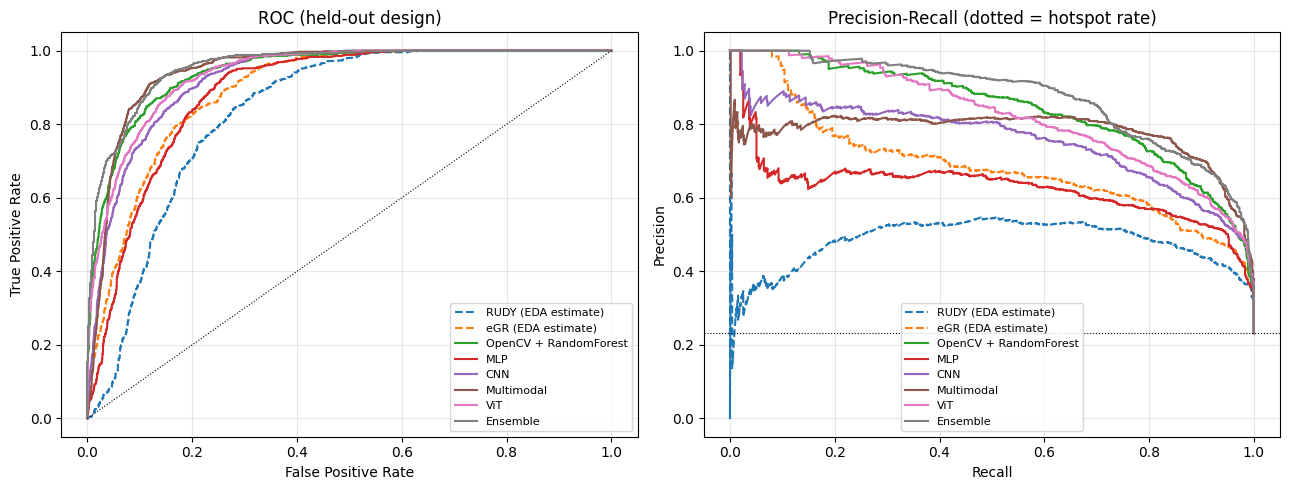

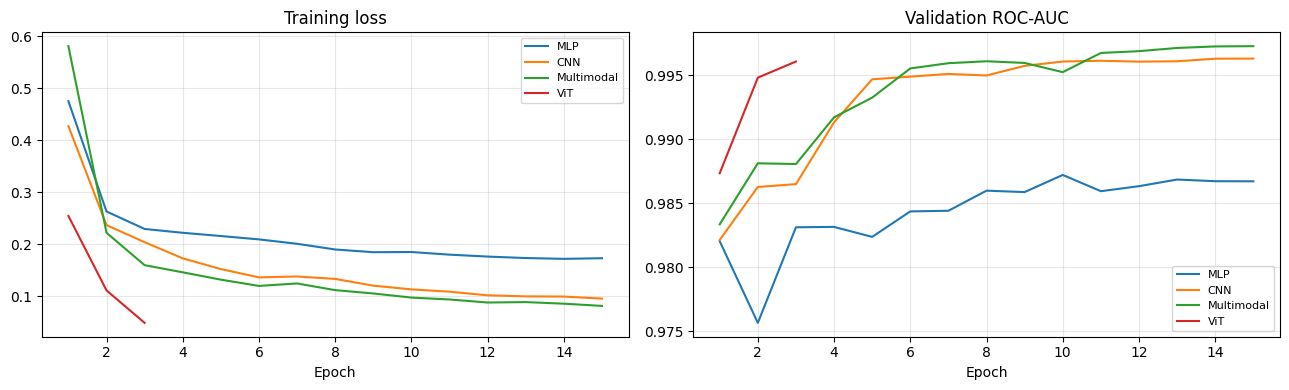

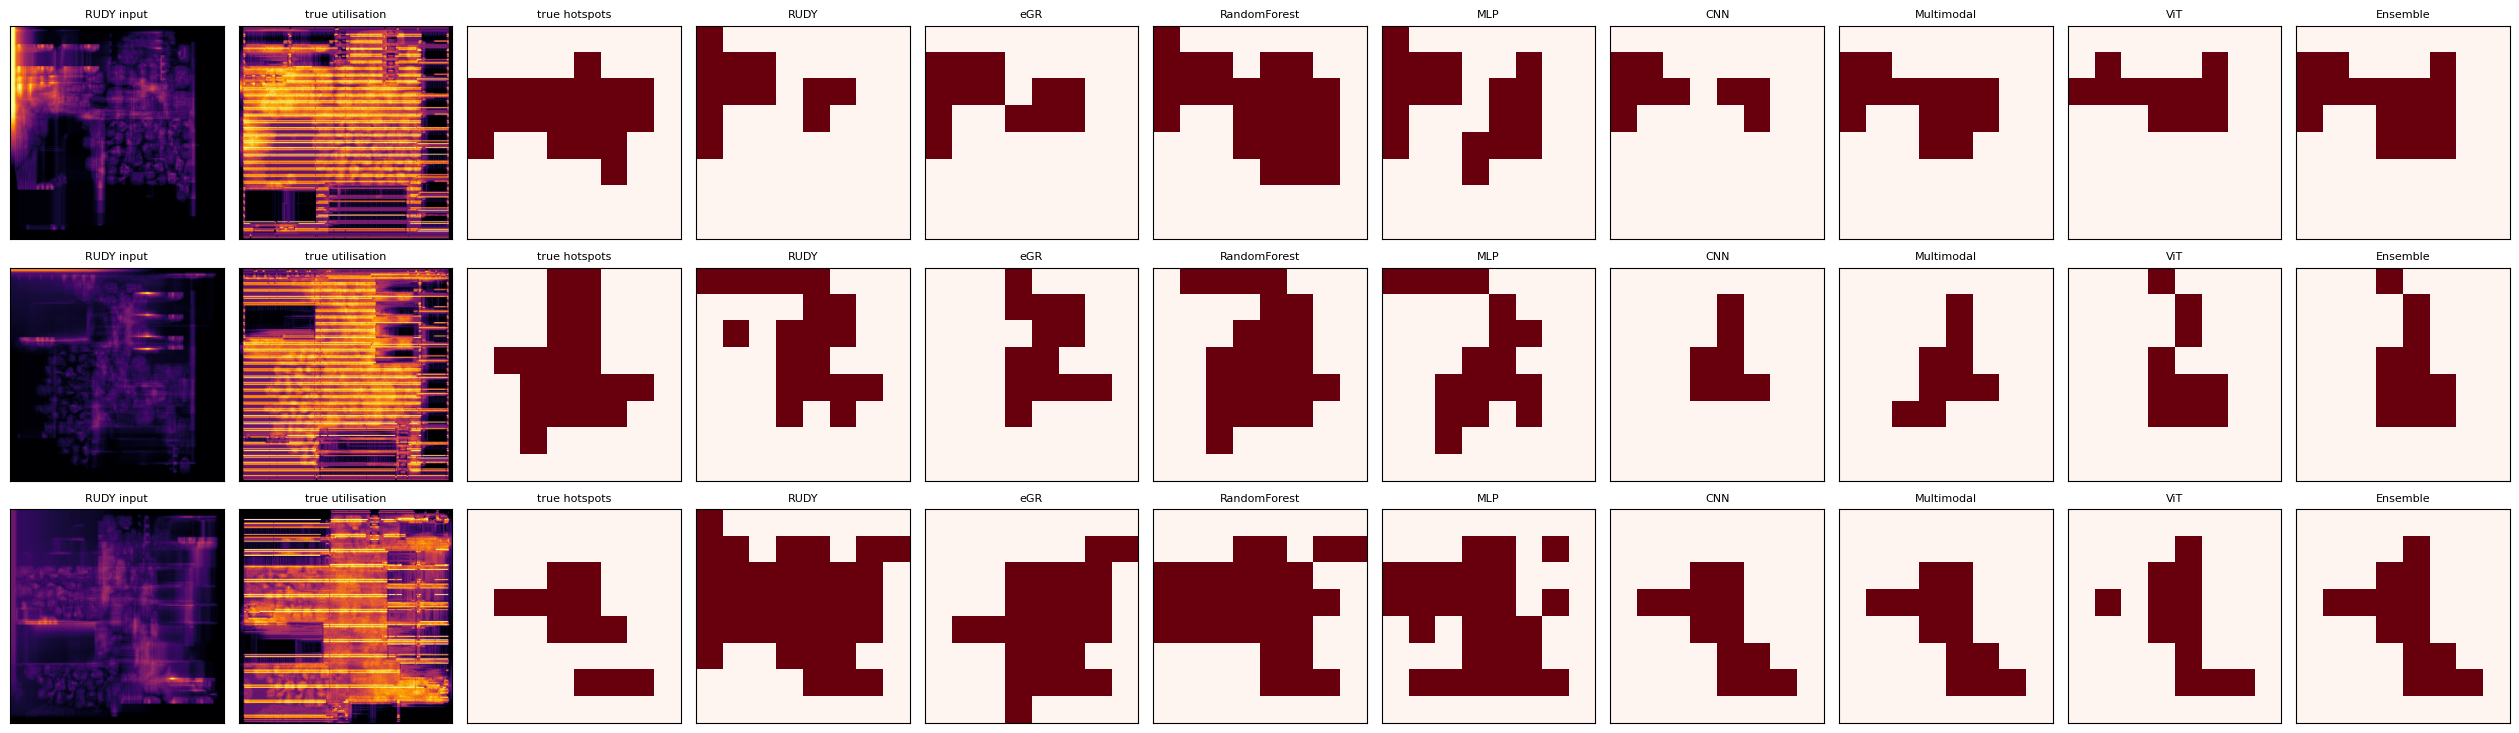

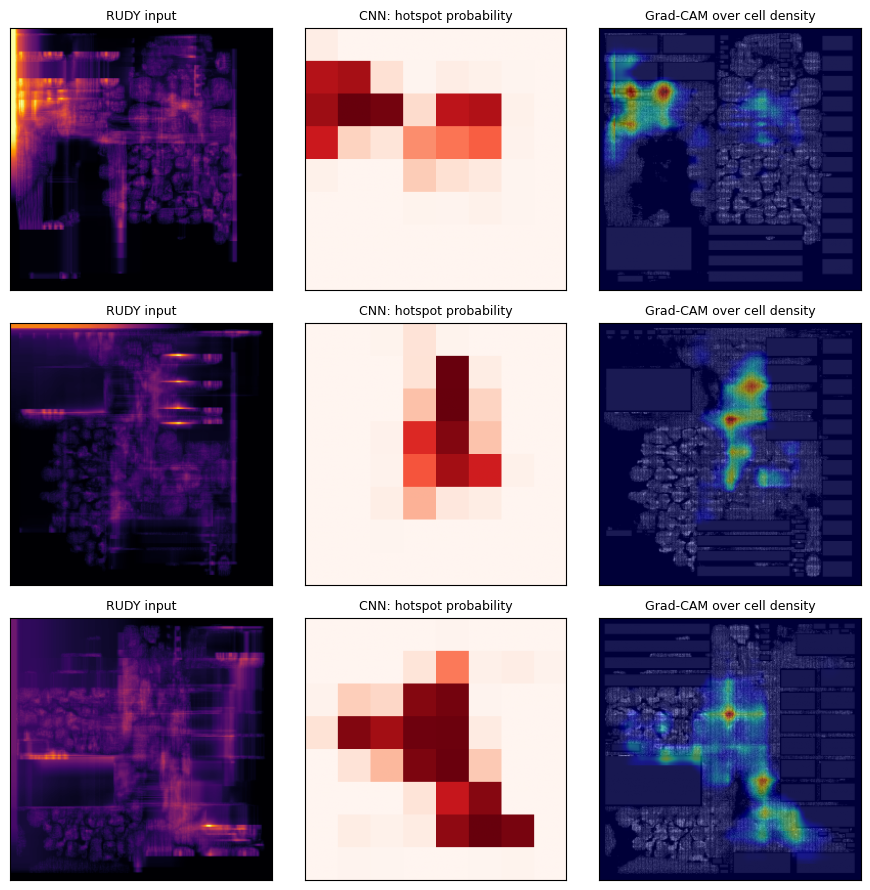

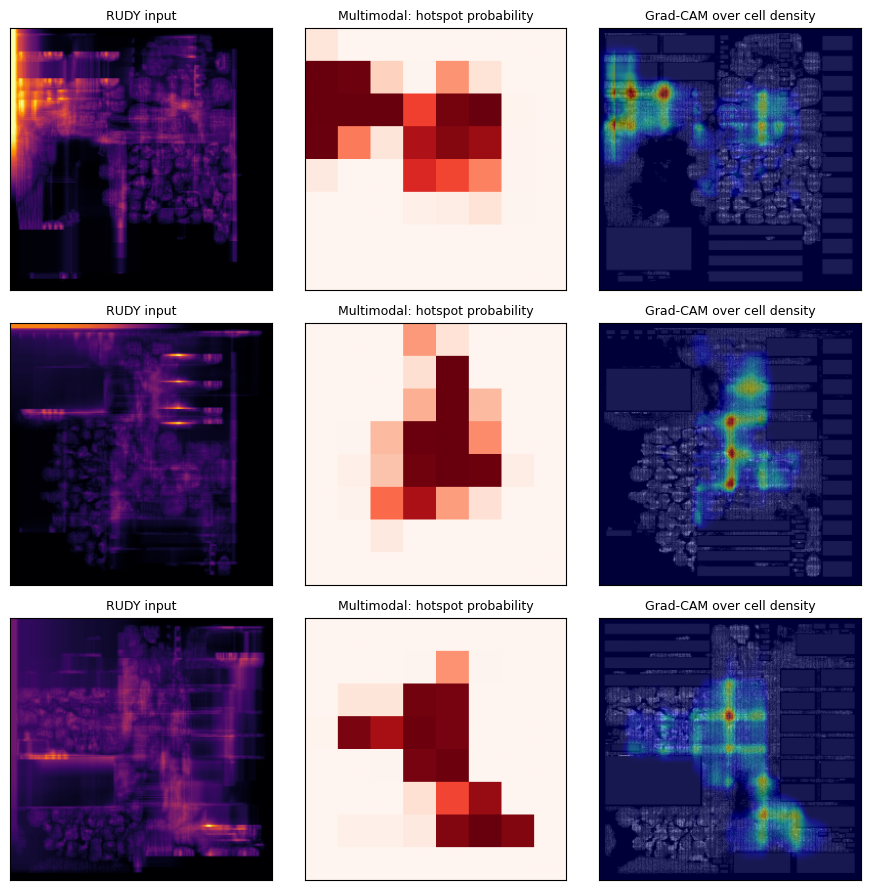

In [5]:
best, means = E.choose_setting(df)
print('mean ROC-AUC of the learned methods:', means, '-> use', best)
E.export_final(CK_ROOT, OUT_ROOT, 'Vortex-small', best)
json.dump({'setting': best, 'mean_roc_auc_learned': means}, open(f'{OUT_ROOT}/chosen_setting.json', 'w'), indent=1)

# 用匯出的模型重畫第一版的圖（模型已快取，只做推論）
data, split, norm, stores = E.prepare('data/processed', DESIGNS, 'Vortex-small', ckpt_dir='checkpoints')
res = E.run(stores, ckpt_dir='checkpoints', out_dir='outputs', augment=(best == 'aug'))
display(res['table'])
yt = stores['test'].flat('y')
E.plot_curves(yt, res['scores'], 'outputs/roc_pr_curves.png'); plt.show()
E.plot_history(res['history'], 'outputs/training_curves.png'); plt.show()
show = [0, len(stores['test'].items) // 2, len(stores['test'].items) - 1]
E.plot_layouts(stores['test'], res['scores'], res['thresholds'], show, 'outputs/hotspot_maps.png'); plt.show()
E.plot_gradcam(res['models']['CNN'], stores['test'], show, 'outputs/gradcam_cnn.png', 'CNN'); plt.show()
E.plot_gradcam(res['models']['Multimodal'], stores['test'], show, 'outputs/gradcam_multimodal.png', 'Multimodal'); plt.show()

## 5. 重新挑選網頁的內建範例，打包下載

In [6]:
!python app/make_demo_set.py
!cd {PROJECT} && rm -f /content/RouteVision_results_v2.zip && zip -q -r /content/RouteVision_results_v2.zip checkpoints outputs demo
from google.colab import files
files.download('/content/RouteVision_results_v2.zip')

）｜模型表現好的例子 Vortex-small_freq_200_mp_1_fpu_60_fpa_1.0_p_2_fi_ar  hot 10.0  RUDY 0.467  eGR 0.560  OpenCV 0.692  Multimodal 0.783  ViT 0.842
）｜模型表現好的例子 Vortex-small_freq_500_mp_2_fpu_50_fpa_1.0_p_1_fi_ap  hot 25.0  RUDY 0.625  eGR 0.634  OpenCV 0.958  Multimodal 0.750  ViT 0.780
）｜模型表現好的例子 Vortex-small_freq_200_mp_2_fpu_60_fpa_1.0_p_2_fi_ar  hot 12.0  RUDY 0.595  eGR 0.625  OpenCV 0.688  Multimodal 0.786  ViT 0.800
eGR 比較準的例子 Vortex-small_freq_500_mp_2_fpu_50_fpa_1.0_p_2_fi_ap  hot 18.0  RUDY 0.732  eGR 0.750  OpenCV 0.848  Multimodal 0.500  ViT 0.615
eGR 比較準的例子 Vortex-small_freq_200_mp_2_fpu_50_fpa_1.0_p_4_fi_ar  hot 8.0  RUDY 0.552  eGR 0.700  OpenCV 0.640  Multimodal 0.571  ViT 0.632
7 layouts -> /content/drive/MyDrive/RouteVision/demo/demo_layouts.npz


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>